In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.mmm_core import (
    CHANNELS,
    CHANNEL_LABELS,
    CONTROLS,
    TARGET,
    load_data,
    metrics,
    rolling_origin_splits
)

from src import mmm_plot_style as ps
ps.apply()

FIG = ROOT / "reports/figures"
TAB = ROOT / "outputs/mmm"

SPLIT = json.load(open(ROOT / "data/processed/split_info.json"))

df = load_data(ROOT / "data/processed/mmm_analysis_ready.csv")

train = df[df.month <= SPLIT["train_end"]].reset_index(drop=True)
test = df[df.month > SPLIT["train_end"]].reset_index(drop=True)

final_controls = CONTROLS + ["average_price_index"]

print(train.shape)
print(test.shape)

(30, 66)
(6, 66)


# 09. Alternative MMM Models

This notebook implements two alternative models to validate the robustness of the final Marketing Mix Model (M3a).

Models:

- Model A: Ridge Regression using log-transformed spend variables
- Model B: Ridge Regression using spend and lagged spend variables

The goal is to compare channel rankings and predictive performance against the final MMM.

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

## Model A: Ridge on log spend

The log transform gives each channel diminishing returns (each extra LKR adds less). Features: the six `log_<channel>_spend` columns from Team 1 plus the five controls of the final model M3a. The scaler sits inside the pipeline, so it is fitted on the training folds only. `alpha` is chosen with the same rolling-origin CV as notebook 07 (18-month minimum, 3-month horizon, 1-month step).

In [3]:
LOG_FEATURES = [
    "log_tv_spend",
    "log_facebook_instagram_spend",
    "log_google_search_spend",
    "log_youtube_spend",
    "log_radio_spend",
    "log_outdoor_spend",
]

FEATURES_A = LOG_FEATURES + final_controls

X_train = train[FEATURES_A]
y_train = train[TARGET]

X_test = test[FEATURES_A]
y_test = test[TARGET]

print("Feature count:", len(FEATURES_A))
print(FEATURES_A)

Feature count: 11
['log_tv_spend', 'log_facebook_instagram_spend', 'log_google_search_spend', 'log_youtube_spend', 'log_radio_spend', 'log_outdoor_spend', 'promotion_discount_pct', 'seasonal_demand_index', 'competitor_pressure_index_0_100', 'economic_sentiment_index_0_100', 'average_price_index']


In [4]:
alphas = np.logspace(-3, 3, 25)

cv_results_a = []

for alpha in alphas:

    fold_rmses = []

    for tr_idx, val_idx in rolling_origin_splits(
        len(train),
        min_train=18,
        horizon=3,
        step=1
    ):

        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha))
        ])

        pipe.fit(
            X_train.iloc[tr_idx],
            y_train.iloc[tr_idx]
        )

        pred = pipe.predict(
            X_train.iloc[val_idx]
        )

        fold_rmses.append(
            metrics(
                y_train.iloc[val_idx],
                pred
            )["RMSE"]
        )

    cv_results_a.append({
        "alpha": alpha,
        "cv_rmse": np.mean(fold_rmses)
    })

cv_results_a = pd.DataFrame(cv_results_a)

best_alpha_a = cv_results_a.loc[
    cv_results_a["cv_rmse"].idxmin(),
    "alpha"
]

print("Best alpha:", best_alpha_a)

Best alpha: 17.78279410038923


In [5]:
model_a = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha_a))
])

model_a.fit(X_train, y_train)

train_pred_a = model_a.predict(X_train)
test_pred_a = model_a.predict(X_test)

train_metrics_a = metrics(y_train, train_pred_a)
test_metrics_a = metrics(y_test, test_pred_a)

print("Train Metrics")
print(train_metrics_a)

print("\nTest Metrics")
print(test_metrics_a)

Train Metrics
{'RMSE': 3936323.7676937315, 'MAE': 3094127.1641314994, 'MAPE_%': 3.8061072906429274, 'R2': 0.7467067006031582}

Test Metrics
{'RMSE': 2151970.0672569526, 'MAE': 1819705.684222805, 'MAPE_%': 2.057638903528984, 'R2': 0.829585409002717}


### Model A Results

The log-spend Ridge model achieved competitive predictive performance, with a test RMSE of approximately 2.15 million LKR and a test R² of 0.83.

Although it does not explicitly model adstock or saturation effects, the logarithmic transformation captures diminishing returns in advertising response. The model performs slightly worse than the final MMM (M3a), suggesting that carry-over and saturation effects provide additional explanatory power beyond simple diminishing returns.

## Model B: Ridge with lagged spend

Carryover is approximated by adding last month's spend (`<channel>_spend_lag1`) next to current spend. The first training month has no previous month, so it is dropped (29 training months). Missing lags are not filled, because filling from later months would use future information.

In [6]:
lag_features = [
    "tv_spend_lag1",
    "facebook_instagram_spend_lag1",
    "google_search_spend_lag1",
    "youtube_spend_lag1",
    "radio_spend_lag1",
    "outdoor_spend_lag1",
]

FEATURES_B = CHANNELS + lag_features + final_controls

print("Feature count:", len(FEATURES_B))

Feature count: 17


In [7]:
train_b = train.dropna(subset=lag_features).reset_index(drop=True)
test_b = test.dropna(subset=lag_features).reset_index(drop=True)

print(train_b.shape)
print(test_b.shape)

(29, 66)
(6, 66)


In [8]:
alphas = np.logspace(-3, 3, 25)

cv_results_b = []

X_train_b = train_b[FEATURES_B]
y_train_b = train_b[TARGET]

for alpha in alphas:

    fold_rmses = []

    for tr_idx, val_idx in rolling_origin_splits(
        len(train_b),
        min_train=18,
        horizon=3,
        step=1
    ):

        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha))
        ])

        pipe.fit(
            X_train_b.iloc[tr_idx],
            y_train_b.iloc[tr_idx]
        )

        pred = pipe.predict(
            X_train_b.iloc[val_idx]
        )

        fold_rmses.append(
            metrics(
                y_train_b.iloc[val_idx],
                pred
            )["RMSE"]
        )

    cv_results_b.append({
        "alpha": alpha,
        "cv_rmse": np.mean(fold_rmses)
    })

cv_results_b = pd.DataFrame(cv_results_b)

best_alpha_b = cv_results_b.loc[
    cv_results_b.cv_rmse.idxmin(),
    "alpha"
]

print("Best alpha:", best_alpha_b)

Best alpha: 10.0


In [9]:
model_b = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha_b))
])

model_b.fit(
    X_train_b,
    y_train_b
)

train_pred_b = model_b.predict(X_train_b)

test_pred_b = model_b.predict(
    test_b[FEATURES_B]
)

train_metrics_b = metrics(
    y_train_b,
    train_pred_b
)

test_metrics_b = metrics(
    test_b[TARGET],
    test_pred_b
)

print("Train Metrics")
print(train_metrics_b)

print("\nTest Metrics")
print(test_metrics_b)

Train Metrics
{'RMSE': 2881690.4677576046, 'MAE': 2205808.887311675, 'MAPE_%': 2.6656664526626033, 'R2': 0.8470946998897702}

Test Metrics
{'RMSE': 1155371.901082101, 'MAE': 1004335.2050427297, 'MAPE_%': 1.1290354390176638, 'R2': 0.9508777867116839}


### Model B results

Model B fits the 6 test months very closely (test RMSE 1.16 m, R² 0.95), but its cross-validation error is the highest of the non-baseline models (3.85 m). Its accuracy is not stable across time periods.

### Why M3a remains the final model

Model B has the best test score of all models (test R² 0.95, MAPE 1.13%), but it is not selected:

- **The model was chosen by cross-validation, not by the test set.** Model B has the worst CV RMSE of the non-baseline models (3.85 m vs 2.96 m for M3a), so its validation error across 10 time-ordered folds is about 30% higher than M3a's.
- **The test set is only 6 months.** A single good 6-month window can happen by chance; choosing the model on it would be overfitting to the test set.
- **Model B is less reliable for attribution.** It estimates 17 coefficients from 29 months without constraints and gives Radio a negative effect, which is not plausible.
- **M3a provides what the next teams need:** non-negative channel effects and smooth response curves for ROI analysis and budget optimisation.

**M3a stays the final model for all hand-offs.**

## Comparison with the notebook 07 models

The alternative models are added to the model comparison table from notebook 07, using the same metrics.

In [10]:
comparison = pd.read_csv(TAB / "07_model_comparison.csv", index_col=0)

alt_rows = pd.DataFrame({
    "Model A Ridge (log spend)": {"train R2": train_metrics_a["R2"], "CV RMSE": cv_results_a["cv_rmse"].min(),
                                  **{f"test {k}": v for k, v in test_metrics_a.items()}},
    "Model B Ridge (lagged spend)": {"train R2": train_metrics_b["R2"], "CV RMSE": cv_results_b["cv_rmse"].min(),
                                     **{f"test {k}": v for k, v in test_metrics_b.items()}},
}).T[comparison.columns]

comparison_09 = pd.concat([comparison, alt_rows])
comparison_09.index.name = "model"
comparison_09.to_csv(TAB / "09_alternative_model_comparison.csv")

show = comparison_09.copy()
for col in ["CV RMSE", "test RMSE", "test MAE"]:
    show[col] = show[col] / 1e6
show.rename(columns={"CV RMSE": "CV RMSE (M)", "test RMSE": "test RMSE (M)", "test MAE": "test MAE (M)"}).round(3)

,train R2,CV RMSE (M),test RMSE (M),test MAE (M),test MAPE_%,test R2
model,,,,,,
M0 Baseline OLS (all controls),0.853,6.379,3.480,2.972,3.393,0.554
"M1 Linear, constrained + ridge",0.690,3.209,2.505,2.425,2.751,0.769
M2 Adstock,0.709,3.092,1.980,1.853,2.093,0.856
M3 Adstock + saturation,0.713,3.077,2.043,1.901,2.139,0.846
M3a + price index,0.709,2.956,1.750,1.563,1.769,0.887
M3b all 6 controls,0.696,2.965,1.993,1.895,2.152,0.854
M3c S-shaped curve (alpha tuned),0.713,3.014,2.131,1.966,2.209,0.833
Model A Ridge (log spend),0.747,3.408,2.152,1.820,2.058,0.830
Model B Ridge (lagged spend),0.847,3.855,1.155,1.004,1.129,0.951


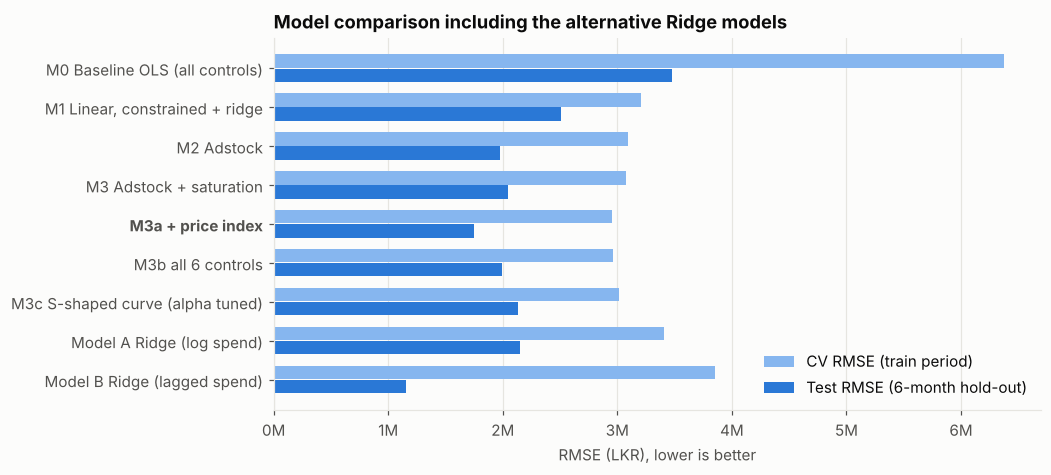

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.4))
order = list(comparison_09.index)[::-1]
y = np.arange(len(order))
ax.barh(y + 0.18, comparison_09.loc[order, "CV RMSE"], height=0.34, color="#86b6ef", label="CV RMSE (train period)")
ax.barh(y - 0.18, comparison_09.loc[order, "test RMSE"], height=0.34, color="#2a78d6", label="Test RMSE (6-month hold-out)")
ax.set_yticks(y, order)
for lbl in ax.get_yticklabels():
    if lbl.get_text().startswith("M3a"):
        lbl.set_fontweight("bold")
ps.millions(ax, "x"); ax.set_xlabel("RMSE (LKR), lower is better")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("Model comparison including the alternative Ridge models")
fig.savefig(FIG / "09_model_comparison.png"); plt.show()

## Channel effects

Ridge coefficients on standardised features give the size of each channel's effect within a model. Plain Ridge does not force effects to be positive, so negative channel coefficients are flagged.

In [12]:
coef_a = pd.Series(
    model_a.named_steps["ridge"].coef_,
    index=FEATURES_A
)

effects_a = coef_a[LOG_FEATURES]

effects_a.sort_values(ascending=False)

log_google_search_spend         1.453476e+06
log_youtube_spend               8.602028e+05
log_outdoor_spend               7.940593e+05
log_tv_spend                    7.479814e+05
log_facebook_instagram_spend    2.116675e+05
log_radio_spend                -1.037143e+06
dtype: float64

In [13]:
effects_a[effects_a < 0]

log_radio_spend   -1.037143e+06
dtype: float64

In [14]:
coef_b = pd.Series(
    model_b.named_steps["ridge"].coef_,
    index=FEATURES_B
)

effects_b = {}

for channel in CHANNELS:

    lag = channel.replace(
        "_spend_lkr",
        "_spend_lag1"
    )

    effects_b[channel] = (
        coef_b[channel]
        + coef_b[lag]
    )

effects_b = pd.Series(effects_b)

effects_b.sort_values(
    ascending=False
)

google_search_spend_lkr         1.266627e+06
facebook_instagram_spend_lkr    1.072323e+06
youtube_spend_lkr               8.442425e+05
outdoor_spend_lkr               6.664032e+05
tv_spend_lkr                    4.238775e+05
radio_spend_lkr                -2.702072e+05
dtype: float64

In [15]:
effects_b[effects_b < 0]


radio_spend_lkr   -270207.190315
dtype: float64

In [16]:
channel_summary = pd.read_csv(TAB / "channel_summary.csv", index_col="channel")

label = CHANNEL_LABELS
ranking_df = pd.DataFrame({
    "M3a ROAS": channel_summary["roas"],
    "Model A": effects_a.rename(index={f"log_{c.replace('_spend_lkr', '')}_spend": label[c] for c in CHANNELS}),
    "Model B": effects_b.rename(index=label),
})

rank_table = ranking_df.rank(ascending=False).astype(int)
rank_table.sort_values("M3a ROAS")

,M3a ROAS,Model A,Model B
Outdoor,1,3,4
YouTube,2,2,3
Google Search,3,1,1
TV,4,4,5
Facebook/Instagram,5,5,2
Radio,6,6,6


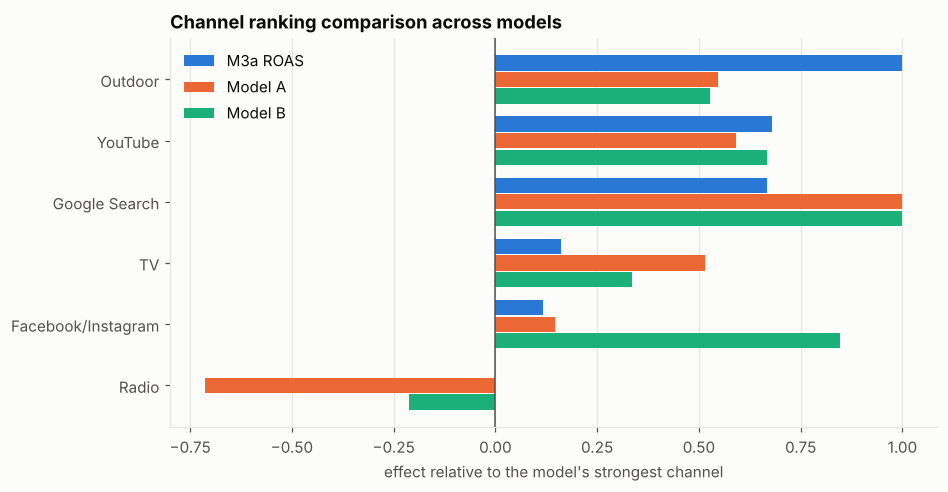

In [17]:
norm = ranking_df / ranking_df.abs().max()   # each model scaled to its own largest effect
order = rank_table.sort_values("M3a ROAS").index[::-1]
model_colors = {"M3a ROAS": "#2a78d6", "Model A": "#eb6834", "Model B": "#1baf7a"}

fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(order))
for k, (col, colr) in enumerate(model_colors.items()):
    ax.barh(y + (1 - k) * 0.27, norm.loc[order, col], height=0.25, color=colr, label=col)
ax.axvline(0, color=ps.INK2, lw=1)
ax.set_yticks(y, order); ax.grid(axis="y", visible=False)
ax.set_xlabel("effect relative to the model's strongest channel")
ax.legend(loc="upper left"); ax.set_title("Channel ranking comparison across models")
fig.savefig(FIG / "09_channel_ranking.png"); plt.show()

## Channel Ranking Comparison

### Channel ranking across methods

| Rank | M3a (ROAS) | Model A (log Ridge) | Model B (lag Ridge) |
|---|---|---|---|
| 1 | Outdoor | Google Search | Google Search |
| 2 | YouTube | YouTube | Facebook/Instagram |
| 3 | Google Search | Outdoor | YouTube |
| 4 | TV | TV | Outdoor |
| 5 | Facebook/Instagram | Facebook/Instagram | TV |
| 6 | Radio | Radio | Radio |

- **Consistent across all three methods:** Google Search and YouTube are strong channels (top 3 in every model), and Radio is the weakest.
- **Method-dependent:** Outdoor ranks 1st in M3a but 3rd–4th in the Ridge models, and Facebook/Instagram ranks 2nd in Model B but 5th in the other two. Conclusions about these two channels should be treated with more caution.
- Both Ridge models gave Radio a negative coefficient. Unconstrained regression can produce implausible negative effects from noise and correlated channels, which supports M3a's non-negative constraint.

Overall, the alternative models confirm the robust findings (Search and YouTube strong, Radio weak) and show which channel conclusions depend on the modelling method.